Arima & SARIMAX (Seasonal AutoRegressive Integrated Moving Average) on Milk Dataset
-

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose # pip install statsmodels
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [2]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv")
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


In [3]:
y_train = df['Milk'][:-12]
y_test = df['Milk'][-12:]
y_train.shape, y_test.shape

((156,), (12,))

ARIMA => Non-Seasonal (p, d, q): The short-term relationship (today vs. yesterday).

SARIMAX => Seasonal (P, D, Q, s): The long-term relationship (this Q1 vs. last year's Q1).

s -> (Seasonal Period)= 4 (Quarterly). If it were monthly, s=12

ARIMA
-

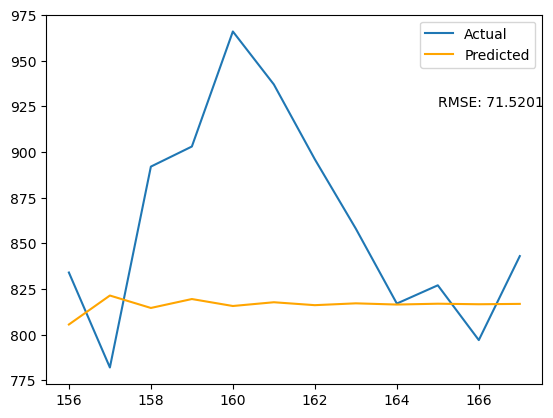

In [23]:
# 1. Define the ARIMA model
# Order (p, d, q): 
# p=1 AR[Auto regressive](Lags), d=Order of Difference to remove trend, q= MA (Moving Average)
model = ARIMA(y_train, order=(3,1,0))

# 2. Fit the model
model_fit = model.fit()

# 3. Predict for the length of the test set (12 observations)
# This returns a Series with the forecasted values
y_pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)

# 4. Calculate RMSE
rms = np.round(root_mean_squared_error(y_test, y_pred), 4)

# 5. Visualize the results
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,y_pred, label='Predicted', color='orange')

# Dynamic text placement for RMSE
plt.text(165,925,f"RMSE: {rms}")
plt.legend()
plt.show()

AR(1) first order Arima with lag = 1

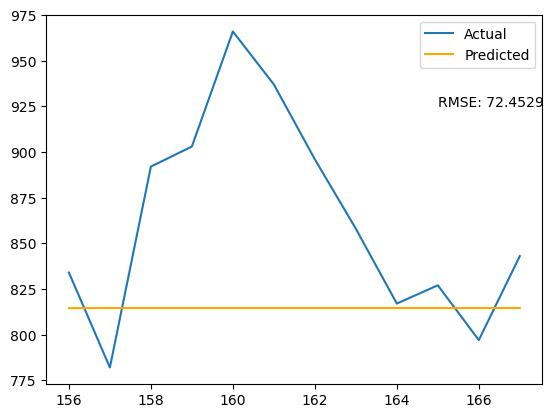

In [8]:
# 1. Define the ARIMA model
# Order (p, d, q): 
# p=1 AR[Auto regressive](Lags), d=Order of Difference to remove trend, q= MA (Moving Average)
model = ARIMA(y_train, order=(1, 1,0))

# 2. Fit the model
model_fit = model.fit()

# 3. Predict for the length of the test set (12 observations)
# This returns a Series with the forecasted values
y_pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)

# 4. Calculate RMSE
rms = np.round(root_mean_squared_error(y_test, y_pred), 4)

# 5. Visualize the results
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,y_pred, label='Predicted', color='orange')

# Dynamic text placement for RMSE
plt.text(165,925,f"RMSE: {rms}")
plt.legend()
plt.show()

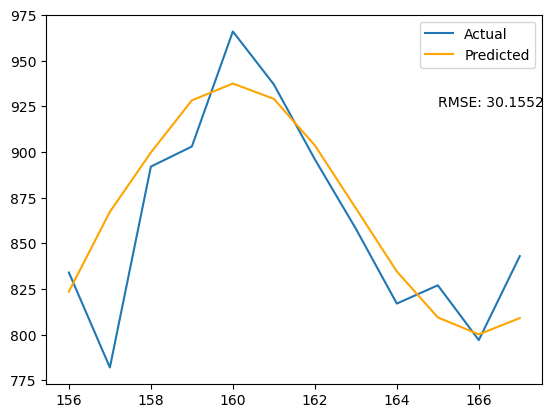

In [24]:
# 1. Define the ARIMA model
# Order (p, d, q): 
# p=2 AR[Auto regressive](Lags), d=Order of Difference to remove trend, q= MA (Moving Average)
model = ARIMA(y_train, order=(3,1,2))

# 2. Fit the model
model_fit = model.fit()

# 3. Predict for the length of the test set (12 observations)
# This returns a Series with the forecasted values
y_pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)

# 4. Calculate RMSE
rms = np.round(root_mean_squared_error(y_test, y_pred), 4)

# 5. Visualize the results
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,y_pred, label='Predicted', color='orange')

# Dynamic text placement for RMSE
plt.text(165,925,f"RMSE: {rms}")
plt.legend()
plt.show()

As our data for milk is seasonal we dont get good ARIMA so we go for SARIMAX Model

SARIMAX (seasonal Arima) [p,d,q,P,D,Q,S]
-

c:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


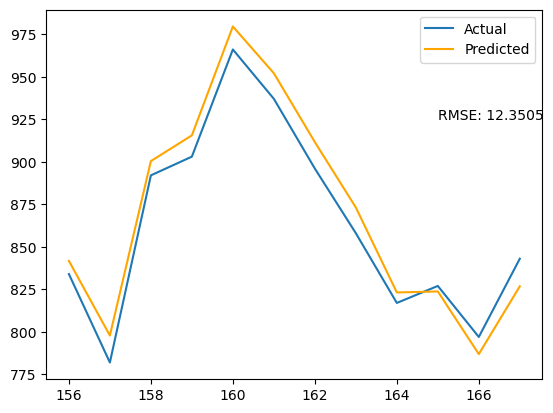

In [26]:
# 1. Define the ARIMA model
# Order (p, d, q): 
# p=2 AR[Auto regressive](Lags), d=Order of Difference to remove trend, q= MA (Moving Average)
model = ARIMA(y_train, order=(3,1,2), seasonal_order=(2,1,1,12)) # seasonal -> P,D,Q,S

# 2. Fit the model
model_fit = model.fit()

# 3. Predict for the length of the test set (12 observations)
# This returns a Series with the forecasted values
y_pred = model_fit.predict(start=len(y_train), end=len(y_train)+len(y_test)-1)

# 4. Calculate RMSE
rms = np.round(root_mean_squared_error(y_test, y_pred), 4)

# 5. Visualize the results
plt.plot(y_test.index,y_test, label='Actual')
plt.plot(y_test.index,y_pred, label='Predicted', color='orange')

# Dynamic text placement for RMSE
plt.text(165,925,f"RMSE: {rms}")
plt.legend()
plt.show()